# 01 — Load and inspect digit localizations

A preliminary visual check of the localizations profile and preview. In this case showing `digits_locs.hdf5` from [notebook 00](00_simulate_digits_picasso.ipynb): review localization quality, inspect the field and zoom into a region.

## 1. Setup

**Picasso** loads and renders the localizations. **Matplotlib** displays the images directly in the notebook.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
from picasso import io, render

project_dir = Path.cwd().resolve()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

## 2. Load the simulated localizations

Run notebook 00 first to create `digits_locs.hdf5` and its matching YAML in `data/simulated/digits_picasso_01/`. Change `data_file` below to inspect another localization file.

| Columns | Meaning |
|---|---|
| `frame` | Frame in which the spot was detected |
| `x`, `y` | Position in camera pixels |
| `photons` | Estimated photons from the spot |
| `sx`, `sy` | Fitted spot widths in camera pixels |
| `bg` | Estimated background photons per camera pixel |
| `lpx`, `lpy` | Estimated localization uncertainty in camera pixels |

These are Picasso's fitted detections from the simulated movie. The views below use the localizations, without ground-truth labels or site overlays.

In [2]:
data_file = project_dir / "data/simulated/digits_picasso_01/digits_locs.hdf5"
if not data_file.is_file() or not data_file.with_suffix(".yaml").is_file():
    raise FileNotFoundError("Run notebook 00 to generate digits_locs.hdf5 and digits_locs.yaml.")
recording_name = data_file.stem.removesuffix("_locs")

locs, info = io.load_locs(str(data_file))
pixel_size_nm = float(info[0]["Pixelsize"])
print(f"Loaded {len(locs):,} valid localizations from {data_file.name}")
print(f"Frames: {locs['frame'].min():,} to {locs['frame'].max():,}")
print(f"Field: {info[0]['Width']} × {info[0]['Height']} camera pixels")
print(f"Simulation pixel size: {pixel_size_nm:g} nm / camera pixel")
locs.head()

Loaded 97,930 valid localizations from digits_locs.hdf5
Frames: 2 to 39,999
Field: 64 × 64 camera pixels
Simulation pixel size: 130 nm / camera pixel


,frame,x,y,photons,sx,sy,bg,lpx,lpy,ellipticity,net_gradient,iterations,chi_square
0,2,5.359529,47.053322,1077.967773,1.033503,1.149866,80.205193,0.066634,0.073619,0.101197,2047.109619,4,3578.519043
1,3,5.333983,47.095047,2194.768311,1.072369,1.135537,80.679398,0.040921,0.043172,0.055629,4314.352539,3,3863.585449
2,4,5.340764,47.012623,751.406860,1.111554,1.246895,76.262589,0.098495,0.109768,0.108542,1267.798706,3,3145.979004
3,5,5.538431,26.278564,1998.357666,1.106444,1.097740,82.188385,0.045178,0.044845,0.007867,3854.032715,3,4774.659668
4,5,36.850105,36.825554,753.023560,1.042520,1.011449,78.625801,0.086038,0.083659,0.029804,1667.867310,4,4044.741943


## 3. Review localization quality

Check the uncertainty, photon counts, background and fitted widths before choosing any cutoffs. Larger uncertainty means a less precise position; unusual widths or photon counts deserve a closer look.

For speed, these histograms and the summary table use roughly 200,000 evenly spaced rows. Plots show the central 99.8% of sampled values; the table includes their minimum and maximum. This step removes no detections.

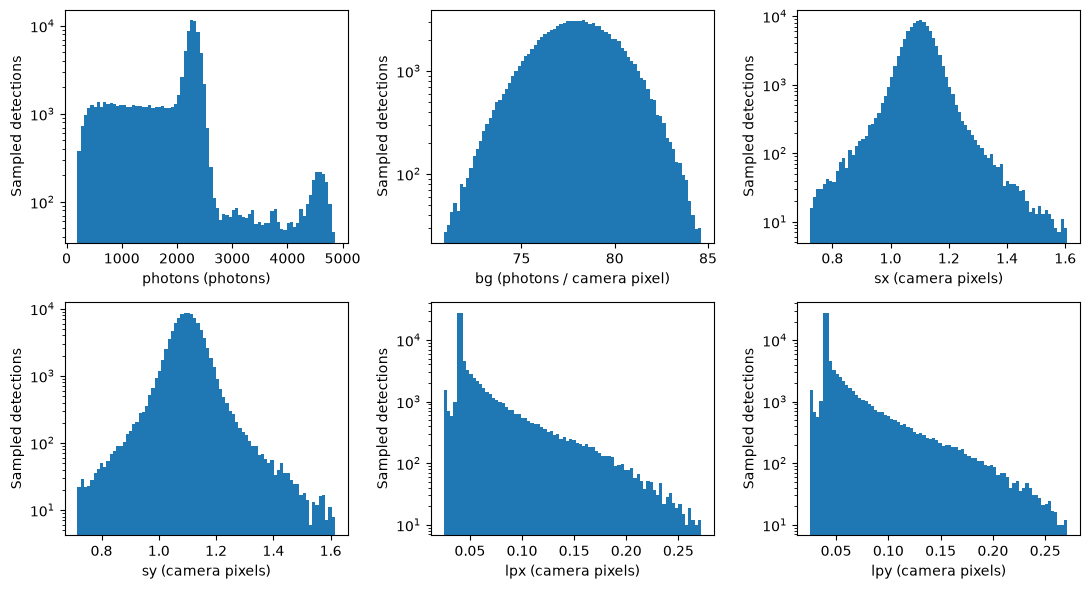

,count,mean,std,min,50%,95%,99%,max
photons,97930.0,1910.490356,763.620483,79.781113,2200.284546,2506.613525,4529.296514,8087.916016
bg,97930.0,77.954674,2.198023,63.148125,77.979317,81.517218,82.970662,87.193489
sx,97930.0,1.099137,0.073888,0.399893,1.098626,1.197500,1.318312,2.667233
sy,97930.0,1.099404,0.073924,0.367382,1.098371,1.197280,1.322811,2.721580
lpx,97930.0,0.056240,0.033911,0.018255,0.041476,0.131428,0.198161,0.457067
lpy,97930.0,0.056276,0.034042,0.019043,0.041485,0.131347,0.199833,0.539313


In [3]:
qc = locs.iloc[::max(1, len(locs) // 200_000)]
fields = ["photons", "bg", "sx", "sy", "lpx", "lpy"]
units = ["photons", "photons / camera pixel", "camera pixels", "camera pixels",
         "camera pixels", "camera pixels"]
quality_summary = qc[fields].describe(percentiles=[0.5, 0.95, 0.99]).T

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, field, unit in zip(axes.flat, fields, units):
    ax.hist(qc[field], bins=80, range=np.percentile(qc[field], [0.1, 99.9]))
    ax.set(xlabel=f"{field} ({unit})", ylabel="Sampled detections", yscale="log")
fig.tight_layout()
plt.show()
quality_summary

## 4. Choose a region

Set `x_min`, `x_max`, `y_min` and `y_max` for the detail view. The default region contains a particle in the current simulation. Oversampling controls how many display pixels represent one camera pixel; a finer grid does not add resolution.

Axes stay in **camera pixels**. Picasso uses the physical pixel size from the simulation metadata (`130 nm` in the current dataset) to set the rendering grid.

In [4]:
cmap = plt.colormaps["magma"].with_extremes(bad="black")

full_oversampling = 8
zoom_oversampling = 64
x_min, x_max = 24, 28
y_min, y_max = 24, 28
height, width = info[0]["Height"], info[0]["Width"]

if not (0 <= x_min < x_max <= width and 0 <= y_min < y_max <= height):
    raise ValueError("Choose increasing x/y bounds within the field of view.")

roi_locs = locs.loc[
    (locs.x >= x_min) & (locs.x < x_max)
    & (locs.y >= y_min) & (locs.y < y_max)
]
if roi_locs.empty:
    raise ValueError("No localizations in this region. Choose different bounds.")

## 5. Inspect the full field

The image counts localizations in each display pixel. The cyan box marks the region shown below. A logarithmic color scale makes both dim and bright structures visible.

To inspect another region, change the bounds above and rerun from section 4.

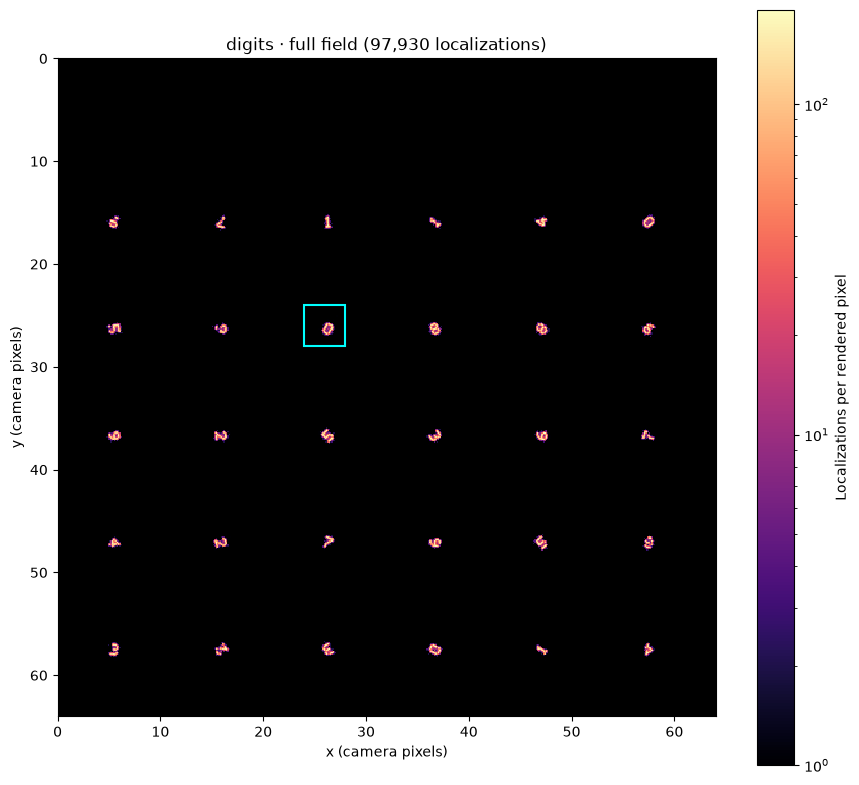

In [5]:
n_full, full_image = render.render(
    locs, info,
    disp_px_size=pixel_size_nm / full_oversampling,
    blur_method=None,
)

full_max = max(2, np.percentile(full_image[full_image > 0], 99.8))
full_fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(
    full_image, cmap=cmap, origin="upper",
    extent=(0, width, height, 0),
    norm=LogNorm(vmin=1, vmax=full_max), interpolation="nearest",
)
ax.add_patch(Rectangle(
    (x_min, y_min), x_max - x_min, y_max - y_min,
    fill=False, edgecolor="cyan", linewidth=1.5,
))
ax.set(
    xlabel="x (camera pixels)", ylabel="y (camera pixels)",
    title=f"{recording_name} · full field ({n_full:,} localizations)",
)
full_fig.colorbar(im, ax=ax, label="Localizations per rendered pixel")
full_fig.tight_layout()
plt.show()

## 6. Inspect the detail

This view uses a finer grid and Picasso's Gaussian rendering: each detection is spread according to its `lpx` and `lpy` uncertainty. Look for separated particles and recognizable site patterns.

Brightness is log-scaled separately for this region and shows rendered density. The original positions and frame numbers remain available in `locs`.

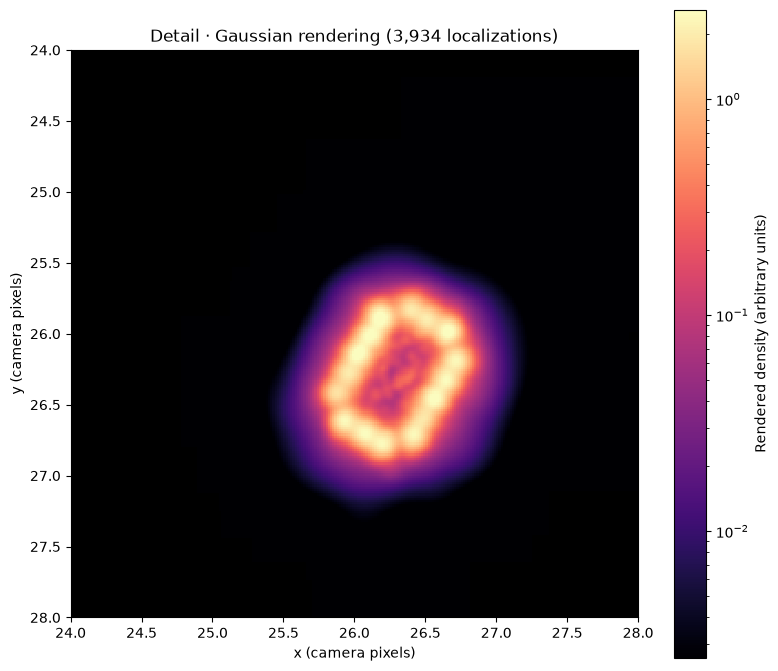

In [6]:
n_zoom, zoom_image = render.render(
    locs, info,
    disp_px_size=pixel_size_nm / zoom_oversampling,
    viewport=((y_min, x_min), (y_max, x_max)),  # Picasso uses (y, x) order.
    blur_method="gaussian",
)
if n_zoom == 0:
    raise ValueError("No localizations in this region. Choose different bounds.")

zoom_max = np.percentile(zoom_image[zoom_image > 0], 99.8)
zoom_fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(
    zoom_image, cmap=cmap, origin="upper",
    extent=(x_min, x_max, y_max, y_min),
    norm=LogNorm(vmin=zoom_max / 1000, vmax=zoom_max),
    interpolation="nearest",
)
ax.set(
    xlabel="x (camera pixels)", ylabel="y (camera pixels)",
    title=f"Detail · Gaussian rendering ({n_zoom:,} localizations)",
)
zoom_fig.colorbar(im, ax=ax, label="Rendered density (arbitrary units)")
zoom_fig.tight_layout()
plt.show()

## 7. Compare the region across time

The same region is shown in three frame ranges with one shared color scale. This gives a quick check of how the rendered pattern varies as different sites blink.

The current simulation adds no drift. Brightness changes alone do not establish motion; this view estimates no drift curve and applies no correction.

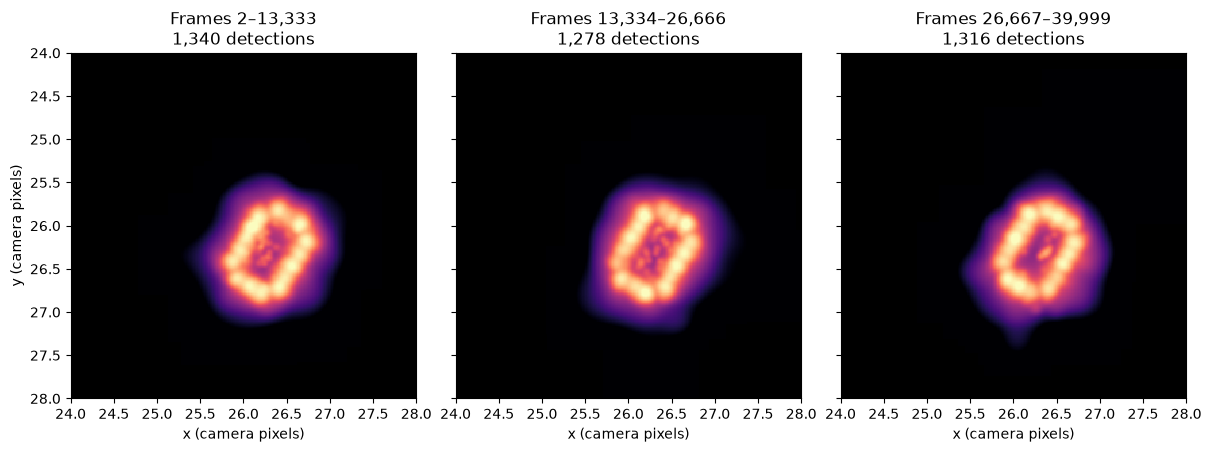

In [7]:
frame_edges = np.linspace(int(locs.frame.min()), int(locs.frame.max()) + 1, 4, dtype=int)
time_images, time_counts = [], []
for start, end in zip(frame_edges[:-1], frame_edges[1:]):
    block = roi_locs.loc[(roi_locs.frame >= start) & (roi_locs.frame < end)]
    n, image = render.render(
        block, info, disp_px_size=pixel_size_nm / zoom_oversampling,
        viewport=((y_min, x_min), (y_max, x_max)), blur_method="gaussian",
    )
    time_images.append(image)
    time_counts.append(int(n))

vmax = max(np.percentile(image[image > 0], 99.8)
           for image in time_images if np.any(image > 0))
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), sharex=True, sharey=True, layout="constrained")
for ax, image, start, end, count in zip(
    axes, time_images, frame_edges[:-1], frame_edges[1:], time_counts
):
    ax.imshow(image, cmap=cmap, origin="upper", extent=(x_min, x_max, y_max, y_min),
              norm=LogNorm(vmin=vmax / 1000, vmax=vmax), interpolation="nearest")
    ax.set(title=f"Frames {start:,}–{end-1:,}\n{count:,} detections",
           xlabel="x (camera pixels)")
axes[0].set_ylabel("y (camera pixels)")
plt.show()

## 8. Optional filter preview

Leave both settings as `None` to retain every detection. After reviewing the distributions, you can test a maximum position uncertainty and/or a minimum photon count. No cutoff is recommended by default.

The preview compares the same region before and after filtering, using identical rendering and contrast. Check whether weak sites disappear. It reports the retained fraction without changing the original data or the input used by notebook 02.

In [8]:
max_uncertainty = None  # Camera pixels; applies to both lpx and lpy.
min_photons = None
keep = np.ones(len(roi_locs), dtype=bool)
if max_uncertainty is not None:
    keep &= (roi_locs.lpx <= max_uncertainty) & (roi_locs.lpy <= max_uncertainty)
if min_photons is not None:
    keep &= roi_locs.photons >= min_photons
print(f"Region retained: {keep.sum():,} / {len(keep):,} detections ({keep.mean():.1%}).")

if keep.all():
    print("No detections removed by this preview.")
elif not keep.any():
    print("These limits remove every detection. Try less restrictive settings.")
else:
    _, filtered_image = render.render(
        roi_locs.loc[keep], info, disp_px_size=pixel_size_nm / zoom_oversampling,
        viewport=((y_min, x_min), (y_max, x_max)), blur_method="gaussian",
    )
    fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
    for ax, image, title in zip(axes, [zoom_image, filtered_image], ["Before", "After"]):
        ax.imshow(image, cmap=cmap, origin="upper", extent=(x_min, x_max, y_max, y_min),
                  norm=LogNorm(vmin=zoom_max / 1000, vmax=zoom_max), interpolation="nearest")
        ax.set(title=title, xlabel="x (camera pixels)")
    axes[0].set_ylabel("y (camera pixels)")
    fig.tight_layout()
    plt.show()

Region retained: 3,934 / 3,934 detections (100.0%).
No detections removed by this preview.
